# Analytics Report: Where Is the Value in a Diamond Inventory?
**Scenario (for this assignment):** a category manager at an online diamond retailer has to decide how to allocate buying budget and pricing effort. **Data:** 53,940 diamond listings (price in USD, carat, cut, colour, clarity, dimensions), from the `seaborn-data` repository (the ggplot2 `diamonds` dataset).
**Business questions**
1. How is the inventory distributed, and where does its value sit?
2. What drives price, and how much?
3. Are there pricing or assortment anomalies we can act on?

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LinearRegression
sns.set_theme(style='whitegrid')
OR, GR, BL, LO = '#C2410C', '#6B7280', '#1D4E89', '#E8A87C'
raw = pd.read_csv('diamonds.csv'); print(raw.shape)

(53940, 10)


## 1. Data quality and preparation

In [2]:
print('Missing values:', int(raw.isna().sum().sum()))
dup = raw.duplicated().sum(); zero = (raw[['x','y','z']]==0).any(axis=1).sum()
imp = ((raw.y > 20) | (raw.z > 20)).sum()
print(f'Exact duplicate rows: {dup} | zero-dimension rows: {zero} | physically implausible size (y or z > 20 mm): {imp}')
d = raw.drop_duplicates()
d = d[(d[['x','y','z']] > 0).all(axis=1) & (d.y < 20) & (d.z < 20)].copy()
print('Rows kept:', len(d), f'({len(d)/len(raw):.2%} of original)')
d['cut']     = pd.Categorical(d['cut'],     ['Fair','Good','Very Good','Premium','Ideal'], ordered=True)
d['color']   = pd.Categorical(d['color'],   list('JIHGFED'), ordered=True)
d['clarity'] = pd.Categorical(d['clarity'], ['I1','SI2','SI1','VS2','VS1','VVS2','VVS1','IF'], ordered=True)
d['ppc'] = d['price'] / d['carat']
d['band'] = pd.cut(d['carat'], [0,0.5,1,1.5,2,6], right=False, labels=['<0.5','0.5-0.99','1.0-1.49','1.5-1.99','2.0+'])

Missing values: 0
Exact duplicate rows: 146 | zero-dimension rows: 20 | physically implausible size (y or z > 20 mm): 3
Rows kept: 53772 (99.69% of original)


## 2. Headline KPIs

In [3]:
kpi = {'Listings': len(d), 'Total listed value ($M)': d.price.sum()/1e6, 'Average price ($)': d.price.mean(),
       'Median price ($)': d.price.median(), 'Average carat': d.carat.mean(),
       'Weighted price per carat ($)': d.price.sum()/d.carat.sum()}
for k,v in kpi.items(): print(f'{k:<30}{v:>14,.2f}')
print('\nMean/median price ratio: %.2f (right-skewed)' % (d.price.mean()/d.price.median()))

Listings                           53,772.00
Total listed value ($M)               211.39
Average price ($)                   3,931.14
Median price ($)                    2,401.00
Average carat                           0.80
Weighted price per carat ($)        4,929.17

Mean/median price ratio: 1.64 (right-skewed)


## 3. Inventory mix vs value mix

In [4]:
def mixtable(col):
    g = d.groupby(col, observed=True).agg(listings=('price','size'), value=('price','sum'), avg_price=('price','mean'), avg_carat=('carat','mean'))
    g['% of listings'] = g.listings/g.listings.sum()*100; g['% of value'] = g.value/g.value.sum()*100
    return g[['listings','% of listings','% of value','avg_price','avg_carat']].round(1)
for c in ['cut','color','clarity']: print(mixtable(c)); print()

           listings  % of listings  % of value  avg_price  avg_carat
cut                                                                 
Fair           1597            3.0         3.3     4340.7        1.0
Good           4888            9.1         9.1     3916.3        0.8
Very Good     12067           22.4        22.7     3981.1        0.8
Premium       13736           25.5        29.8     4578.4        0.9
Ideal         21484           40.0        35.2     3462.2        0.7

       listings  % of listings  % of value  avg_price  avg_carat
color                                                           
J          2802            5.2         7.1     5326.4        1.2
I          5406           10.1        13.0     5079.8        1.0
H          8265           15.4        17.5     4476.2        0.9
G         11254           20.9        21.3     3999.1        0.8
F          9517           17.7        16.8     3726.8        0.7
E          9774           18.2        14.2     3079.8        

In [5]:
g = d.groupby('band', observed=True).agg(listings=('price','size'), value=('price','sum'), ppc=('ppc','median'), avg_price=('price','mean'))
g['% of listings'] = (g.listings/g.listings.sum()*100).round(1); g['% of value'] = (g.value/g.value.sum()*100).round(1)
print(g[['listings','% of listings','% of value','avg_price','ppc']].round(0))
s = d.price.sort_values(ascending=False).reset_index(drop=True)
for p in (.01,.10,.20): print(f'Top {p:.0%} of listings hold {s.iloc[:int(len(s)*p)].sum()/s.sum():.1%} of listed value')
big = d[d.carat >= 1]; print(f'\nStones of 1 carat or more: {len(big)/len(d):.1%} of listings, {big.price.sum()/d.price.sum():.1%} of value')

          listings  % of listings  % of value  avg_price     ppc
band                                                            
<0.5         17608           33.0         7.0      792.0  2250.0
0.5-0.99     17180           32.0        20.0     2497.0  3490.0
1.0-1.49     12787           24.0        37.0     6143.0  5030.0
1.5-1.99      4068            8.0        21.0    10906.0  6704.0
2.0+          2129            4.0        15.0    14851.0  7159.0
Top 1% of listings hold 4.6% of listed value
Top 10% of listings hold 34.4% of listed value
Top 20% of listings hold 54.2% of listed value

Stones of 1 carat or more: 35.3% of listings, 73.1% of value


## 4. What drives price?

In [6]:
print(d[['carat','depth','table','x','y','z','price']].corr()['price'].round(2))
X = pd.get_dummies(pd.concat([np.log(d.carat).rename('log_carat'), d[['cut','color','clarity']].astype(str)], axis=1), drop_first=False)
for c,b in [('cut_Fair',1),('color_J',1),('clarity_I1',1)]: pass
X = X.drop(columns=['cut_Fair','color_J','clarity_I1'])
y = np.log(d.price)
m = LinearRegression().fit(X, y)
print('\nR2 of log-price model:', round(m.score(X, y), 3))
coef = pd.Series(m.coef_, index=X.columns)
print('Price elasticity of carat: %.2f (a 10%% larger stone costs about %.0f%% more)' % (coef['log_carat'], (1.1**coef['log_carat']-1)*100))
prem = ((np.exp(coef.drop('log_carat'))-1)*100).round(1)
print('\nPrice premium vs base level (J colour, I1 clarity, Fair cut), same carat:'); print(prem.sort_values(ascending=False))

carat    0.92
depth   -0.01
table    0.13
x        0.89
y        0.89
z        0.88
price    1.00
Name: price, dtype: float64



R2 of log-price model: 0.983
Price elasticity of carat: 1.88 (a 10% larger stone costs about 20% more)

Price premium vs base level (J colour, I1 clarity, Fair cut), same carat:
clarity_IF       204.3
clarity_VVS1     176.8
clarity_VVS2     157.7
clarity_VS1      125.1
clarity_VS2      109.8
clarity_SI1       80.8
color_D           66.7
color_E           58.0
clarity_SI2       53.4
color_F           51.7
color_G           42.1
color_H           29.7
cut_Ideal         17.6
cut_Premium       15.0
color_I           14.9
cut_Very Good     12.5
cut_Good           8.5
dtype: float64


## 5. Anomalies and opportunities

In [7]:
# (a) The cut paradox
cp = d.groupby('cut', observed=True).agg(avg_price=('price','mean'), avg_carat=('carat','mean'), listings=('price','size')).round(2)
print(cp); print()
print('Median $/carat by cut within carat band:'); print(d.pivot_table(index='band', columns='cut', values='ppc', aggfunc='median', observed=True).round(0))

           avg_price  avg_carat  listings
cut                                      
Fair         4340.68       1.04      1597
Good         3916.28       0.85      4888
Very Good    3981.09       0.81     12067
Premium      4578.36       0.89     13736
Ideal        3462.21       0.70     21484

Median $/carat by cut within carat band:
cut         Fair    Good  Very Good  Premium   Ideal
band                                                
<0.5      2178.0  1848.0     2044.0   2252.0  2364.0
0.5-0.99  2995.0  3360.0     3492.0   3430.0  3584.0
1.0-1.49  3965.0  4609.0     5062.0   4872.0  5542.0
1.5-1.99  4973.0  5934.0     6683.0   6760.0  7188.0
2.0+      5657.0  7243.0     7369.0   7094.0  7318.0


In [8]:
# (b) The round-number effect around 1 carat
sub = d[d.carat.between(0.90, 1.10)]
t = sub.groupby('carat').agg(listings=('price','size'), avg_price=('price','mean'), ppc=('ppc','mean')).round(0)
print(t.loc[[0.90,0.95,0.96,0.97,0.98,0.99,1.00,1.01,1.02,1.05,1.10]])
a, b = d[d.carat==0.99], d[d.carat==1.00]
print(f'\n0.99 ct: {len(a)} listings, avg ${a.price.mean():,.0f} | 1.00 ct: {len(b)} listings, avg ${b.price.mean():,.0f} | jump {b.price.mean()/a.price.mean()-1:.0%} for 0.01 ct')
print('1.00 ct listings are', round(len(b)/len(a),1), 'times as many as 0.99 ct')

       listings  avg_price     ppc
carat                             
0.90       1484     3940.0  4377.0
0.95         65     4014.0  4225.0
0.96        103     3623.0  3774.0
0.97         59     4026.0  4151.0
0.98         31     3470.0  3541.0
0.99         23     4406.0  4451.0
1.00       1546     5249.0  5249.0
1.01       2238     5509.0  5454.0
1.02        883     5598.0  5489.0
1.05        361     5782.0  5506.0
1.10        275     5921.0  5383.0

0.99 ct: 23 listings, avg $4,406 | 1.00 ct: 1546 listings, avg $5,249 | jump 19% for 0.01 ct
1.00 ct listings are 67.2 times as many as 0.99 ct


In [9]:
# (c) Poor-quality stones: how much of the inventory is low grade?
low = d[(d.clarity.isin(['I1','SI2'])) & (d.color.isin(['I','J']))]
print(f'Low clarity (I1/SI2) AND low colour (I/J): {len(low)} listings = {len(low)/len(d):.1%} of listings, {low.price.sum()/d.price.sum():.1%} of value')
top = d[(d.clarity.isin(['VVS1','VVS2','IF'])) & (d.color.isin(['D','E','F']))]
print(f'High clarity (VVS/IF) AND top colour (D-F): {len(top)} listings = {len(top)/len(d):.1%} of listings, {top.price.sum()/d.price.sum():.1%} of value, avg carat {top.carat.mean():.2f}')

Low clarity (I1/SI2) AND low colour (I/J): 1525 listings = 2.8% of listings, 4.8% of value
High clarity (VVS/IF) AND top colour (D-F): 4767 listings = 8.9% of listings, 6.7% of value, avg carat 0.50


## 6. Visualizations

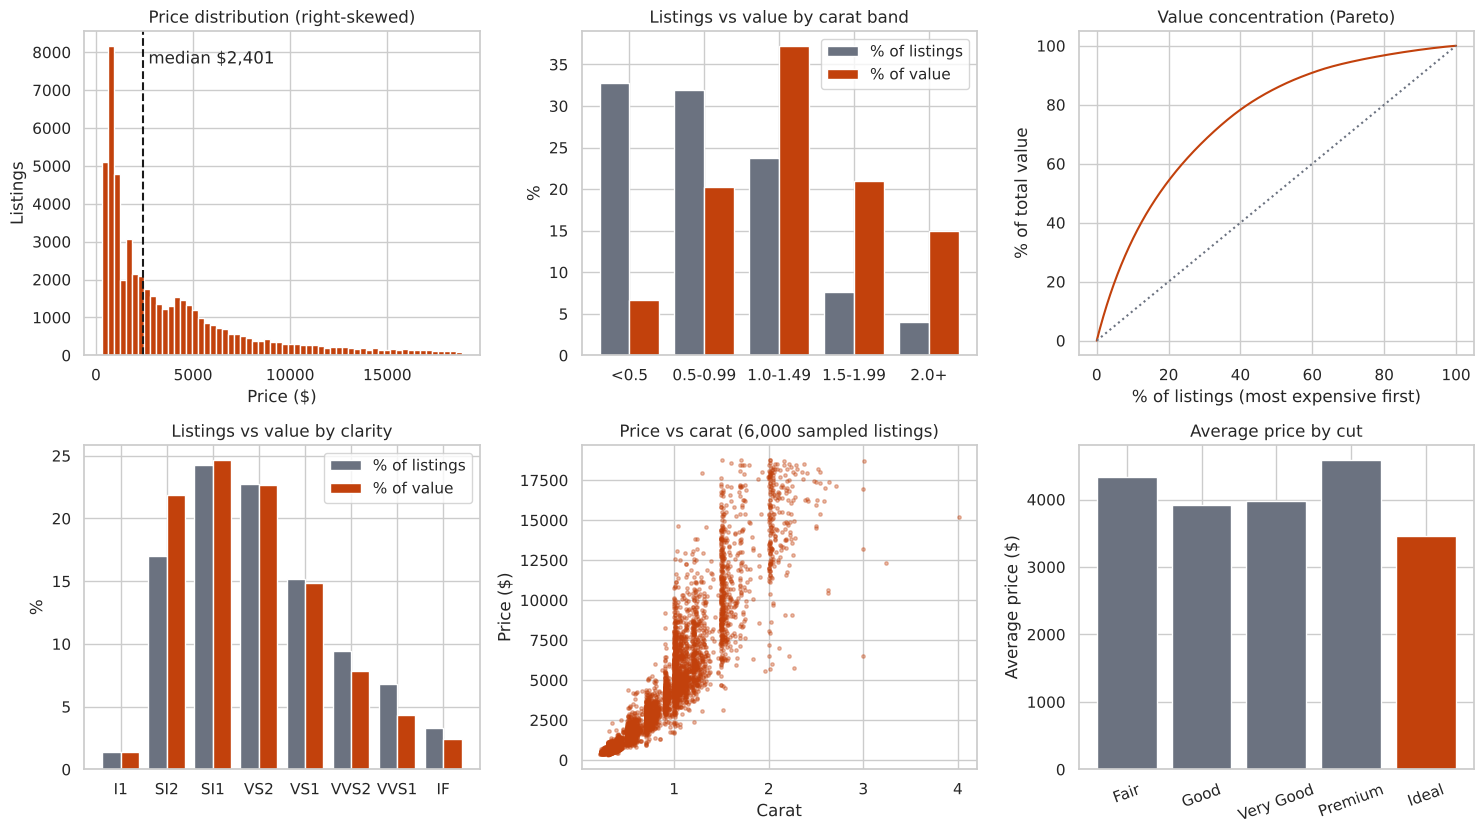

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8.5))
# 1 price distribution
ax[0,0].hist(d.price, bins=60, color=OR, edgecolor='white'); ax[0,0].axvline(d.price.median(), color='k', ls='--'); ax[0,0].text(d.price.median()+300, ax[0,0].get_ylim()[1]*.9, f'median ${d.price.median():,.0f}')
ax[0,0].set(title='Price distribution (right-skewed)', xlabel='Price ($)', ylabel='Listings')
# 2 value by carat band: listings vs value
g = d.groupby('band', observed=True).agg(n=('price','size'), v=('price','sum')); x = np.arange(len(g))
ax[0,1].bar(x-.2, g.n/g.n.sum()*100, .4, color=GR, label='% of listings'); ax[0,1].bar(x+.2, g.v/g.v.sum()*100, .4, color=OR, label='% of value')
ax[0,1].set_xticks(x, g.index); ax[0,1].set(title='Listings vs value by carat band', ylabel='%'); ax[0,1].legend()
# 3 Pareto
s = d.price.sort_values(ascending=False).cumsum()/d.price.sum()*100
ax[0,2].plot(np.arange(len(s))/len(s)*100, s.values, color=OR); ax[0,2].plot([0,100],[0,100], color=GR, ls=':')
ax[0,2].set(title='Value concentration (Pareto)', xlabel='% of listings (most expensive first)', ylabel='% of total value')
# 4 clarity mix
g = d.groupby('clarity', observed=True).agg(n=('price','size'), v=('price','sum')); x = np.arange(len(g))
ax[1,0].bar(x-.2, g.n/g.n.sum()*100, .4, color=GR, label='% of listings'); ax[1,0].bar(x+.2, g.v/g.v.sum()*100, .4, color=OR, label='% of value')
ax[1,0].set_xticks(x, g.index); ax[1,0].set(title='Listings vs value by clarity', ylabel='%'); ax[1,0].legend()
# 5 price vs carat
sm = d.sample(6000, random_state=1); ax[1,1].scatter(sm.carat, sm.price, s=6, alpha=.35, color=OR)
ax[1,1].set(title='Price vs carat (6,000 sampled listings)', xlabel='Carat', ylabel='Price ($)')
# 6 cut
cp = d.groupby('cut', observed=True)[['price','carat']].mean(); ax[1,2].bar(cp.index.astype(str), cp.price, color=[GR,GR,GR,GR,OR])
ax[1,2].set(title='Average price by cut', ylabel='Average price ($)'); ax[1,2].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.savefig('fig1_dashboard.png', dpi=140)

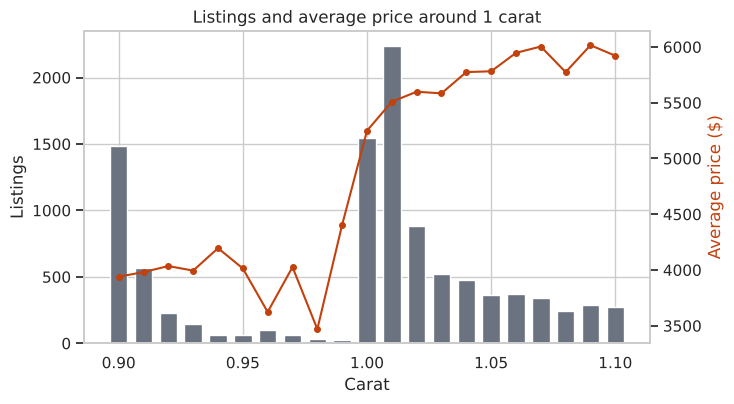

In [11]:
fig, ax = plt.subplots(figsize=(7.5,4.2))
t = d[d.carat.between(.9,1.1)].groupby('carat').agg(n=('price','size'), p=('price','mean'))
ax.bar(t.index, t.n, width=.007, color=GR); ax.set(title='Listings and average price around 1 carat', xlabel='Carat', ylabel='Listings')
ax2 = ax.twinx(); ax2.plot(t.index, t.p, color=OR, marker='o', ms=4); ax2.set_ylabel('Average price ($)', color=OR); ax2.grid(False)
plt.tight_layout(); plt.savefig('fig2_round_carat.png', dpi=150)

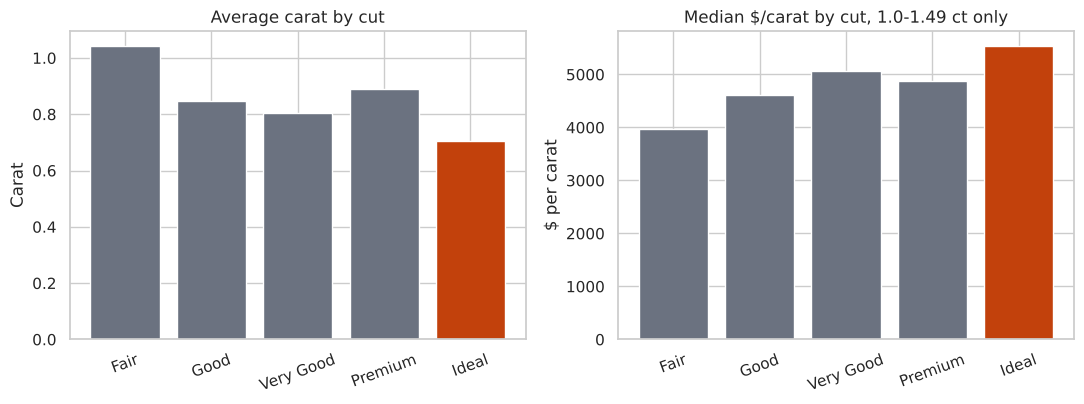

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
cp = d.groupby('cut', observed=True).agg(p=('price','mean'), c=('carat','mean'))
ax[0].bar(cp.index.astype(str), cp.c, color=[GR,GR,GR,GR,OR]); ax[0].set(title='Average carat by cut', ylabel='Carat'); ax[0].tick_params(axis='x', rotation=20)
pv = d[d.band=='1.0-1.49'].groupby('cut', observed=True)['ppc'].median()
ax[1].bar(pv.index.astype(str), pv.values, color=[GR,GR,GR,GR,OR]); ax[1].set(title='Median $/carat by cut, 1.0-1.49 ct only', ylabel='$ per carat'); ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.savefig('fig3_cut_paradox.png', dpi=150)

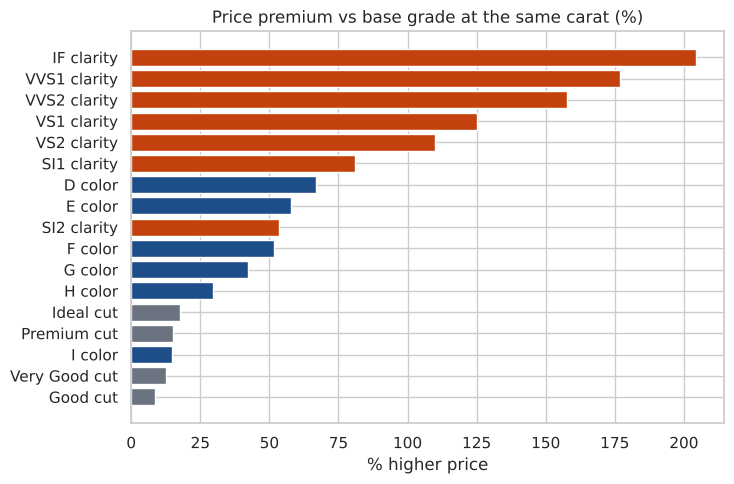

In [13]:
p = prem.copy(); p.index = [i.split('_',1)[1] + ' ' + i.split('_',1)[0] for i in p.index]
fig, ax = plt.subplots(figsize=(7.5,5))
p = p.sort_values(); ax.barh(p.index, p.values, color=[OR if 'clarity' in i else (BL if 'color' in i else GR) for i in p.index])
ax.set(title='Price premium vs base grade at the same carat (%)', xlabel='% higher price')
plt.tight_layout(); plt.savefig('fig4_premiums.png', dpi=150)